# Assessing change over time for repeat draw clients
Going to take a look at any change over time for clients with multiple blood draws

In [1]:
import pandas as pd
import arivale_data_interface as adi
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# apply settings so the lib knows where the data is
adi.apply_isb_config()

import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from statannotations.Annotator import Annotator

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))
# Now you can import your file
from regression_functions import *

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [2]:
abx_covar = pd.read_csv("../data/rh_abx_covar_alphadivs_scfa.csv", dtype={'public_client_id':str})

In [3]:
abx_covar.days_in_program.max()

769.0

## Use snapshot to select repeat participants

In [4]:
div = adi.get_snapshot("microbiome_diversity")
div.dropna(subset=['days_in_program'], inplace=True)
shannon_div = div[["diversity_shannon", "public_client_id", "days_in_program", "vendor_dashboard", "observed_otus_20000"]]

In [5]:
shannon_div = shannon_div[shannon_div.public_client_id.isin(abx_covar.public_client_id)].sort_values(by='public_client_id')

In [6]:
# Grab the ids that show up more than once
shannon_dup_id = (shannon_div[shannon_div.public_client_id.duplicated()
                  ].public_client_id.tolist())

shannon_dup = shannon_div[shannon_div.public_client_id.isin(shannon_dup_id)]

In [7]:
shannon_dup['public_client_id'].nunique() # Sizeable number!

838

In [8]:
# Now subset these folks from our study
abx_covar_repeat = abx_covar[abx_covar.public_client_id.isin(shannon_dup_id)]
abx_covar_repeat_small = (abx_covar_repeat[[
    'public_client_id', 
    'days_in_program',
    'abx_recency']].copy())

In [9]:
# Want to be able to compare the dates
abx_covar_repeat_small.rename(columns={
    'days_in_program':'days_in_program_questionnaire'}, inplace=True)

In [10]:
shannon_repeats = shannon_dup.merge(
    abx_covar_repeat_small,
    how ='left',
    on="public_client_id")

In [11]:
shannon_repeats.abx_recency.value_counts()

abx_recency
none      1313
twelve     397
three      276
Name: count, dtype: int64

In [12]:
shannon_repeats.public_client_id.nunique()

838

We will want to know whether or not the stool sample in question is associated with the abx questionnaire or not. 

In [13]:
shannon_repeats['paired_stool_questionnare'] = (
    (shannon_repeats['days_in_program'] - shannon_repeats['days_in_program_questionnaire'] <= 30)
    .map({True: 'Yes', False: 'No'}))

In [14]:
shannon_repeats_baseline = shannon_repeats[shannon_repeats['paired_stool_questionnare'] == 'Yes'].drop_duplicates(
    subset='public_client_id')
len(shannon_repeats_baseline)

838

In [15]:
shannon_repeats_followup = shannon_repeats[shannon_repeats['paired_stool_questionnare'] == 'No']

In [16]:
shannon_repeats_followup.sort_values(by=['public_client_id', 'days_in_program'])
shannon_repeats_followup_first = shannon_repeats_followup.drop_duplicates(subset='public_client_id', keep='first')
len(shannon_repeats_followup_first)

830

In [17]:
# Samples at day 2 and 25
# To close to one another
#  Drop this client 

to_drop = list(set(shannon_repeats_baseline.public_client_id) - 
               set(shannon_repeats_followup_first.public_client_id))

# shannon_repeats[shannon_repeats.public_client_id == to_drop[0]]

In [18]:
shannon_repeats_baseline = shannon_repeats_baseline[shannon_repeats_baseline.public_client_id != to_drop[0]]

**Now let's join the data**

In [19]:
all_followup_timepoints = pd.concat([shannon_repeats_baseline, shannon_repeats_followup_first])
# all_followup_timepoints.sort_values(by=['public_client_id','days_in_program']).head() 

<Axes: xlabel='days_in_program', ylabel='diversity_shannon'>

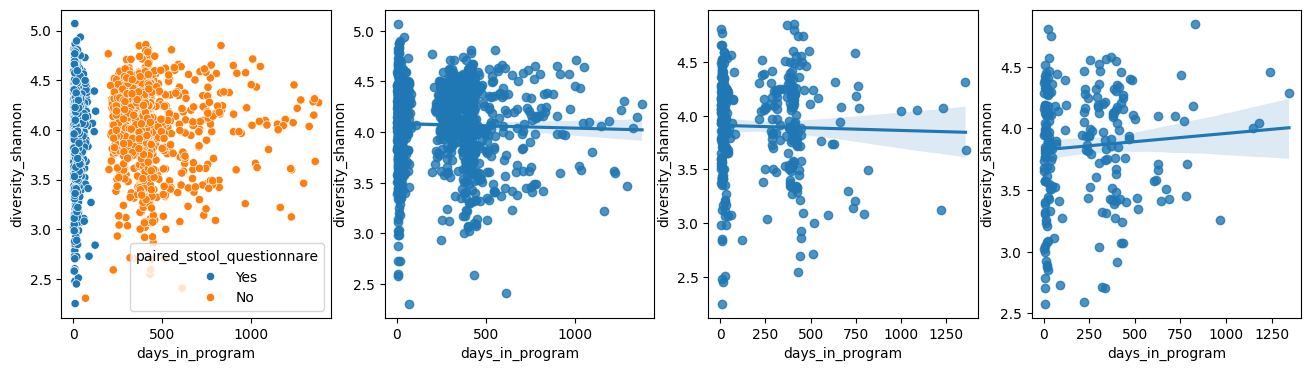

In [20]:
all_followup_timepoints_none = all_followup_timepoints[all_followup_timepoints['abx_recency'] == 'none']
all_followup_timepoints_three = all_followup_timepoints[all_followup_timepoints['abx_recency'] == 'three']
all_followup_timepoints_twelve = all_followup_timepoints[all_followup_timepoints['abx_recency'] == 'twelve']


fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes = axes.flatten()

sns.scatterplot(data=all_followup_timepoints, x='days_in_program', y='diversity_shannon', hue='paired_stool_questionnare', ax=axes[0])
sns.regplot(data=all_followup_timepoints_none, x='days_in_program', y='diversity_shannon', ax=axes[1])
sns.regplot(data=all_followup_timepoints_twelve, x='days_in_program', y='diversity_shannon', ax=axes[2])
sns.regplot(data=all_followup_timepoints_three, x='days_in_program', y='diversity_shannon', ax=axes[3])

## Now let's use the alpha diversity measures that we have re-calculated
This is from rarefied data too.

In [21]:
abx_df_obs_feats = (abx_covar[[
    'public_client_id',
    'days_in_program', 
    'observed_features', 
    'berger_parker',
    'shannon_index']].copy())

abx_df_obs_feats.rename(columns={
    'days_in_program':'days_in_program_abx_df'}, inplace=True)

In [22]:
baseline_merge = (shannon_repeats_baseline[[
    'public_client_id',
    'days_in_program',
    'days_in_program_questionnaire',
    'paired_stool_questionnare',
    'abx_recency']].copy())

In [23]:
baseline_alphas = baseline_merge.merge(
    abx_df_obs_feats, 
    how='left',
    on='public_client_id')
baseline_alphas.head()

,public_client_id,days_in_program,days_in_program_questionnaire,paired_stool_questionnare,abx_recency,days_in_program_abx_df,observed_features,berger_parker,shannon_index
0,01002412,13.0,10.0,Yes,none,10.0,121.494626,0.130139,3.388333
1,01003555,8.0,0.0,Yes,none,0.0,85.943252,0.563537,2.115057
2,01003758,21.0,5.0,Yes,none,5.0,85.751037,0.264530,2.824300
3,01004350,23.0,1.0,Yes,none,1.0,71.069951,0.282135,2.901893
4,01004596,7.0,0.0,Yes,none,0.0,80.413747,0.360647,2.811232


In [24]:
sum(baseline_alphas['days_in_program_questionnaire'] == baseline_alphas['days_in_program_abx_df'])

837

In [25]:
# Now we can drop the extra column
baseline_alphas.drop(columns=['days_in_program_abx_df'], inplace=True)

In [26]:
baseline_alphas.abx_recency.value_counts()

abx_recency
none      557
twelve    165
three     115
Name: count, dtype: int64

## Grab follow-up days_in_program

In [27]:
follow_up_small = (shannon_repeats_followup_first[[
    'public_client_id',
    'days_in_program',
    'paired_stool_questionnare',
    'abx_recency']].copy())

## Find follow-up stool samples

In [28]:
asvs = pd.read_csv("/proj/gibbons/arivale_16S/data/asvs.csv")
metadata = pd.read_csv("/proj/gibbons/arivale_16S/data/metadata.csv")
asvs_meta = pd.merge(asvs, metadata[["id", "public_client_id", "sex", "age", "days_in_program"]], on="id")
asvs_meta.head()

,id,hash,count,public_client_id,sex,age,days_in_program
0,22001612560016|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,1285,01884560,F,42.0,8.0
1,22001612560023|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,2431,01192392,F,31.0,3.0
2,22001612560062|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,4908,01349735,F,54.0,8.0
3,22001612560065|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,3944,01735977,F,58.0,16.0
4,22001612560067|GFM-1079-001,c2d3fc09212e226b3a2c3398a1af9436,5990,01363623,F,52.0,11.0


In [29]:
tax = pd.read_csv("/proj/gibbons/arivale_16S/data/taxonomy.csv")
tax = tax.drop("sequence", axis=1).rename(columns={"id": "hash"})
asvs_meta_tax = pd.merge(asvs_meta, tax, on="hash")
# asvs_meta_tax.head()

In [30]:
# We have to subset down to only the id/date combinations we're interested in
follow_up_small = follow_up_small.sort_values(by='days_in_program')
asvs_meta_tax = asvs_meta_tax.dropna(
    subset=['public_client_id', 'days_in_program']
).sort_values(by='days_in_program')

asvs_abx = pd.merge_asof(
    asvs_meta_tax, follow_up_small,
    by="public_client_id",
    on="days_in_program",
    direction="nearest", 
    tolerance=30.0).dropna(                     # Keep only folks with 
    subset=['id', 'paired_stool_questionnare']) # stool and abx questionnaire data
# asvs_abx.head()

In [31]:
taxa = asvs_abx.drop(columns=["hash"], axis=1)
# taxa.head()

In [32]:
# Make a new column, similar to before, but exclude the species in the name
taxa = taxa.assign(taxa_genus_level = taxa.Kingdom.astype(str) + '_' + \
                   taxa.Phylum.astype(str) + '_' + taxa.Class.astype(str) + '_' + \
                   taxa.Order.astype(str) + '_' + taxa.Family.astype(str) + '_' + \
                   taxa.Genus.astype(str))
# taxa.head()

In [33]:
# taxa['taxa_genus_level'].nunique()

In [34]:
genera = taxa.groupby(["id", "taxa_genus_level"])["count"].sum().reset_index()
genera.taxa_genus_level.nunique()

465

In [35]:
too_many_nans_genus = taxa['taxa_genus_level'].str.count('_nan') > 3

# Drop those rows
genus_more_specific = taxa[~too_many_nans_genus].sort_values(by = ['public_client_id'])
# genus_more_specific.head()

<Axes: >

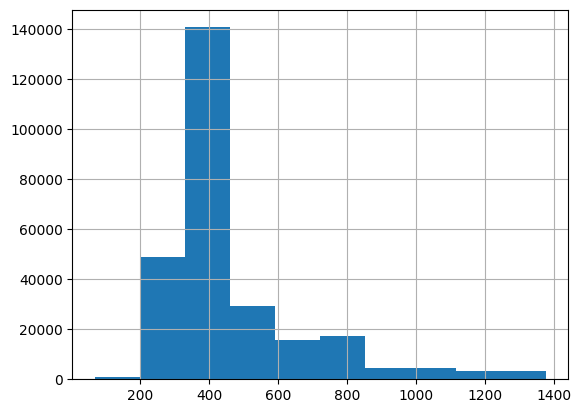

In [36]:
# Before pivoting the table, let's make sure that these dates are large
genus_more_specific.days_in_program.hist()

In [37]:
genus_more_specific.days_in_program.min()

68.0

In [38]:
# Create MultiIndex for pivot table
arrays = [genus_more_specific['public_client_id'], genus_more_specific['taxa_genus_level']]
index = pd.MultiIndex.from_arrays(arrays, names=('public_client_id','taxa_genus_level'))

# Pivot df with taxa as columns, public_client_id as index, and counts as values
taxa_melt_genus = pd.DataFrame(data = {'count': genus_more_specific['count'].to_numpy()}, index=index)

taxa_pivot_genus = taxa_melt_genus.pivot_table(index='public_client_id', columns='taxa_genus_level', 
                                         values='count', aggfunc='sum', fill_value = 0)

taxa_pivot_genus = taxa_pivot_genus.dropna(how='any')
# taxa_pivot_genus.head()

In [39]:
taxa_pivot_genus.reset_index(inplace=True)
taxa_pivot_genus.columns.name = None
# taxa_pivot_genus

In [40]:
eukaryota_cols = taxa_pivot_genus.columns[taxa_pivot_genus.columns.str.contains('Eukaryota')]

In [41]:
taxa_pivot_genus.drop(columns=eukaryota_cols, inplace=True)

In [42]:
taxa_pivot_genus

,public_client_id,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Arcanobacterium,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_F0332,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Mobiluncus,...,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Pyramidobacter,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Synergistes,Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Verrucomicrobia_Verrucomicrobiae_Chthoniobacterales_Xiphinematobacteraceae_Candidatus_Xiphinematobacter,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia
0,01002412,0,0,0,0,0,10,0,7,0,...,0,0,0,0,0,0,0,0,0,6510
1,01003555,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,65
2,01003758,0,0,0,0,0,10,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,01004350,0,0,0,0,0,0,0,0,0,...,0,0,0,0,20,0,0,0,0,247
4,01004596,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1772
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
825,01995874,3252,0,0,0,0,0,0,0,0,...,0,0,0,602,2515,0,0,0,0,20
826,01997909,0,0,0,0,0,133,0,0,0,...,0,0,0,0,0,0,0,0,0,1253
827,01998999,57,0,0,0,0,10,0,0,0,...,0,0,0,0,0,0,0,0,0,422
828,HX400498,0,0,0,0,0,0,0,0,0,...,0,0,0,0,19,0,0,0,0,53


In [43]:
multiple_use = pd.read_csv('../data/abx_multiple_use_df.csv', dtype={'public_client_id':str})

In [44]:
multiple_use

,Unnamed: 0,public_client_id,days_in_program,meds_antibiotics_last_3_months,meds_blood_sugar,meds_cholesterol,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_nan,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,...,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Pedosphaerales_Pedosphaeraceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_nan_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_nan_nan_nan,Eukaryota_Euglenozoa_Euglenida_Aphagea_Aphagea_fa_Distigma,Eukaryota_Euglenozoa_Euglenida_Aphagea_Aphagea_fa_nan,Eukaryota_Euglenozoa_Euglenida_nan_nan_nan,Eukaryota_Incertae_Sedis_Incertae_Sedis_cl_Incertae_Sedis_or_Incertae_Sedis_fa_Blastocystis,Eukaryota_Parabasalia_Tritrichomonadea_Tritrichomonadea_or_Tritrichomonadea_fa_Dientamoeba
0,4141,01194014,13.0,Yes,No,No,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,6606,01194014,981.0,Yes,No,No,0.0,0.0,0.0,0.0,...,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,6477,01241633,769.0,Yes,Yes,Yes,0.0,0.0,0.0,0.0,...,0.0,0.0,116.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,6629,01241633,1152.0,Yes,No,Yes,0.0,0.0,0.0,0.0,...,0.0,0.0,1071.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2075,01277837,1.0,Yes,No,No,0.0,0.0,0.0,0.0,...,0.0,0.0,1158.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,6376,01277837,676.0,Yes,No,No,0.0,0.0,0.0,0.0,...,0.0,0.0,3616.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,1113,01617024,0.0,Yes,No,No,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,6003,01617024,370.0,Yes,No,No,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,4596,01729794,28.0,Yes,No,No,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,6636,01729794,1179.0,Yes,No,No,0.0,0.0,0.0,0.0,...,200.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [45]:
clean_follow_up_df = taxa_pivot_genus[~taxa_pivot_genus.public_client_id.isin(multiple_use.public_client_id)]

In [46]:
clean_follow_up_df

,public_client_id,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter,Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomassiliicoccaceae_Methanomassiliicoccus,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_Candidatus_Methanogranum,Archaea_Euryarchaeota_Thermoplasmata_Methanomassiliicoccales_Methanomethylophilaceae_nan,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Arcanobacterium,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_F0332,Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Mobiluncus,...,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Pyramidobacter,Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Synergistes,Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma,Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan,Bacteria_Tenericutes_Mollicutes_Mycoplasmatales_Mycoplasmataceae_Mycoplasma,Bacteria_Verrucomicrobia_Verrucomicrobiae_Chthoniobacterales_Xiphinematobacteraceae_Candidatus_Xiphinematobacter,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_Cerasicoccus,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan,Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia
0,01002412,0,0,0,0,0,10,0,7,0,...,0,0,0,0,0,0,0,0,0,6510
1,01003555,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,65
2,01003758,0,0,0,0,0,10,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,01004350,0,0,0,0,0,0,0,0,0,...,0,0,0,0,20,0,0,0,0,247
4,01004596,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1772
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
825,01995874,3252,0,0,0,0,0,0,0,0,...,0,0,0,602,2515,0,0,0,0,20
826,01997909,0,0,0,0,0,133,0,0,0,...,0,0,0,0,0,0,0,0,0,1253
827,01998999,57,0,0,0,0,10,0,0,0,...,0,0,0,0,0,0,0,0,0,422
828,HX400498,0,0,0,0,0,0,0,0,0,...,0,0,0,0,19,0,0,0,0,53


In [47]:
# clean_follow_up_df.to_csv("../data/repeat_client_follow_up_genera_counts.csv", index=False)

# Now go to R and rareify!

In [48]:
# Used vegan to calculate our alpha diversity metrics
followup_alphas = pd.read_csv("../data/abx_followups_alphadivs_rarefied.csv", dtype={'public_client_id':str})

In [49]:
# oops I didn't keep the dates when I took this to R, we should merge them back!
followup_alphas = follow_up_small.merge(followup_alphas, how='left', on='public_client_id')
followup_alphas_long = followup_alphas.copy()

In [50]:
followup_alphas.days_in_program.mean()

446.5710843373494

### Make both long and wide form df

In [51]:
# Now going to try and make long_df to use in a lmm
followup_alphas_long.rename(columns={'observed_features_followup':'observed_features'}, inplace=True)
followup_alphas_long.rename(columns={'shannon_index_followup':'shannon_index'}, inplace=True)
followup_alphas_long.rename(columns={'berger_parker_followup':'berger_parker'}, inplace=True)

In [52]:
# First let's drop the helper paired stool column from both questionnaires
baseline_alphas.drop(columns='paired_stool_questionnare', inplace=True)
followup_alphas_long.drop(columns='paired_stool_questionnare', inplace=True)

baseline_alphas.drop(columns='days_in_program_questionnaire', inplace=True)

Okay now the follow-up here has the same column names as the baseline.

Check the wide forget follow-up next.

In [53]:
followup_alphas.drop(columns=['paired_stool_questionnare','abx_recency'], inplace=True)
followup_alphas.rename(columns={'days_in_program':'days_in_program_followup'}, inplace=True)

In [54]:
followup_baselines_all = baseline_alphas.merge(followup_alphas, how='left', on='public_client_id') # used in wide df

In [55]:
# followup_baselines_all.abx_recency.value_counts()

Okay let's switch back to the long-df generation. make a copy of the baseline df just in case.

In [56]:
baseline_alphas_long = baseline_alphas.copy()

In [57]:
abx_covar_followups = abx_covar[['public_client_id', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5',
                                 'meds_blood_sugar', 'meds_cholesterol', 'sex', 'age',
                                 'centered_eGFR','abx_recency_three', 'abx_recency_twelve']].copy()

abx_covar_followups = abx_covar_followups[abx_covar_followups.public_client_id.isin(baseline_alphas_long.public_client_id)]

In [58]:
baseline_alphas_long = baseline_alphas_long.merge(abx_covar_followups, how='left', on='public_client_id')
followup_alphas_long = followup_alphas_long.merge(abx_covar_followups, how='left', on='public_client_id')

In [59]:
# Make a days_since_baseline column
baseline_alphas_long.set_index('public_client_id', inplace=True)
followup_alphas_long.set_index('public_client_id', inplace=True)

In [60]:
baseline_alphas_long.loc[:,'dsb'] = 0
followup_alphas_long.loc[:,'dsb'] = followup_alphas_long.loc[:,'days_in_program'] - baseline_alphas_long.loc[:,'days_in_program']

In [61]:
followup_alphas_long.dsb.mean() 

426.25060240963853

In [62]:
followup_alphas_long.dsb.median()

388.0

In [63]:
fu_long_df = pd.concat([baseline_alphas_long, followup_alphas_long], axis=0)

In [64]:
fu_long_df.sort_values(by=['public_client_id','days_in_program']).head()

,days_in_program,abx_recency,observed_features,berger_parker,shannon_index,PC1,PC2,PC3,PC4,PC5,meds_blood_sugar,meds_cholesterol,sex,age,centered_eGFR,abx_recency_three,abx_recency_twelve,dsb
public_client_id,,,,,,,,,,,,,,,,,,
01002412,13.0,none,121.494626,0.130139,3.388333,0.065735,-0.018133,-0.037775,0.115139,0.044114,No,No,F,52,-2.724972,0,0,0.0
01002412,296.0,none,70.053217,0.154362,2.915998,0.065735,-0.018133,-0.037775,0.115139,0.044114,No,No,F,52,-2.724972,0,0,283.0
01003555,8.0,none,85.943252,0.563537,2.115057,0.054544,0.006107,0.018013,-0.139370,0.006274,No,No,M,47,-10.814785,0,0,0.0
01003555,418.0,none,86.079702,0.622268,1.978151,0.054544,0.006107,0.018013,-0.139370,0.006274,No,No,M,47,-10.814785,0,0,410.0
01003758,21.0,none,85.751037,0.264530,2.824300,0.061326,-0.007885,-0.040712,0.066417,0.015187,No,No,F,33,18.116838,0,0,0.0


Awesome, the above shows that the says since baseline was calculated appropriately. 

In [65]:
vendor_df = shannon_repeats[['public_client_id','days_in_program','vendor_dashboard']].copy()

In [66]:
vendor_df = vendor_df.sort_values(by='days_in_program')
fu_long_df = fu_long_df.sort_values(by='days_in_program')
long_df = pd.merge_asof(
    fu_long_df, 
    vendor_df,
    on='days_in_program',
    by='public_client_id').sort_values(
    by=['public_client_id','days_in_program'])

For some reason vendor information was not available for all folks' second time sample, so we will drop those individuals.

In [67]:
drop_na_vendor = long_df[long_df.vendor_dashboard.isna()].public_client_id.tolist()
len(drop_na_vendor)

2

In [68]:
long_df = long_df[~long_df.public_client_id.isin(drop_na_vendor)]

In [69]:
## Add BMI as something that changed over time

In [70]:
weights = adi.get_snapshot("weight")[[
    "BMI_CALC",
    "public_client_id",
    "days_in_program"]].dropna()

In [71]:
weights = weights.sort_values(by='days_in_program')
long_df = long_df.sort_values(by='days_in_program')

long_bmi = pd.merge_asof(
    long_df, 
    weights,
    on='days_in_program',
    by='public_client_id')

In [72]:
drop_na_bmi = long_bmi[long_bmi.BMI_CALC.isna()].public_client_id.tolist()
len(drop_na_bmi)

13

In [73]:
long_bmi = long_bmi[~long_bmi.public_client_id.isin(drop_na_bmi)]

Let's do some visualization of the two time points.

### Visualization

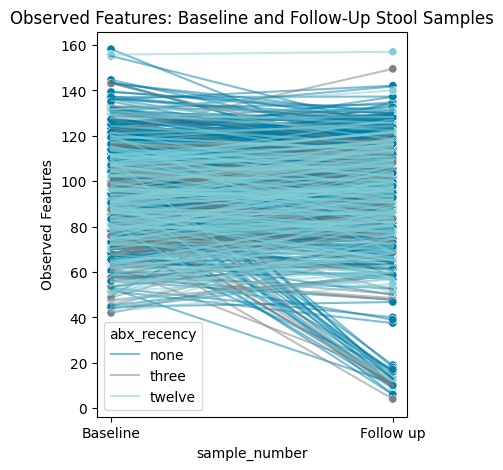

In [74]:
long_bmi = long_bmi.sort_values(['public_client_id', 'dsb'])
long_bmi['sample_number'] = long_bmi.groupby('public_client_id').cumcount()
lp_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#808080'} 

plt.figure(figsize=(4,5))

# Draw lines (this is the magic)
sns.lineplot(
    data=long_bmi,
    x='sample_number',
    y='observed_features',
    hue='abx_recency',
    units='public_client_id',  # tells seaborn: one line per subject
    estimator=None,            # prevents averaging
    alpha=0.5,
    palette=lp_pal,
    legend=True
)

# Overlay points
sns.scatterplot(
    data=long_bmi,
    x='sample_number',
    y='observed_features',
    hue='abx_recency',
    palette=lp_pal,
    legend=False
)

plt.xticks([0, 1], ['Baseline', 'Follow up'])
plt.ylabel('Observed Features')
plt.title('Observed Features: Baseline and Follow-Up Stool Samples')

plt.show()

Interestingly, there's a group of people whose observed features completely tank in the second sample. Let's investigate this.

### Investigate outliers

In [75]:
under_thirtyfive = long_bmi[long_bmi.observed_features < 35].sort_values(
    by=['vendor_dashboard', 'days_in_program'])[[
    'public_client_id',
    'days_in_program',
    'observed_features',
    'vendor_dashboard',
    'abx_recency'
    ]].copy()
under_thirtyfive.head()

,public_client_id,days_in_program,observed_features,vendor_dashboard,abx_recency
844,01556865,219.0,13.0,Second Genome,none
848,01148226,223.0,9.0,Second Genome,three
852,01990337,226.0,17.0,Second Genome,none
860,01045282,230.0,13.0,Second Genome,none
858,01276094,230.0,12.0,Second Genome,twelve


In [76]:
under_thirtyfive.observed_features.mean()

12.032256274217696

In [77]:
under_thirtyfive.vendor_dashboard.value_counts()

vendor_dashboard
Second Genome    31
Name: count, dtype: int64

In [78]:
# under_thirtyfive.sort_values(by='public_client_id')

**Interestingly, this is all mostly Second Genome**

In [79]:
under_thirtyfive[under_thirtyfive.vendor_dashboard == 'Second Genome'].days_in_program.describe()

count     31.000000
mean     274.129032
std       47.828682
min      219.000000
25%      237.500000
50%      247.000000
75%      324.000000
max      358.000000
Name: days_in_program, dtype: float64

In [80]:
(long_bmi[(long_bmi.vendor_dashboard == 'Second Genome') & (long_bmi.days_in_program > 200)]) # ['observed_features'].hist()

,public_client_id,days_in_program,abx_recency,observed_features,berger_parker,shannon_index,PC1,PC2,PC3,PC4,...,meds_cholesterol,sex,age,centered_eGFR,abx_recency_three,abx_recency_twelve,dsb,vendor_dashboard,BMI_CALC,sample_number
973,01002412,296.0,none,70.053217,0.154362,2.915998,0.065735,-0.018133,-0.037775,0.115139,...,No,F,52,-2.724972,0,0,283.0,Second Genome,24.159536,1
917,01011802,262.0,none,63.733888,0.178466,2.936963,-0.148973,0.038228,0.677017,0.187470,...,No,F,40,11.381456,0,0,251.0,Second Genome,21.916299,1
1038,01013950,325.0,twelve,92.976382,0.230303,3.127839,0.066643,-0.021249,-0.040087,0.030152,...,No,F,43,7.633551,0,1,248.0,Second Genome,21.934424,1
1019,01016090,314.0,none,80.855355,0.197796,2.914240,0.065220,-0.014399,-0.028084,0.018724,...,No,M,68,-5.144253,0,0,285.0,Second Genome,33.719004,1
876,01021026,242.0,none,73.141775,0.230487,3.161556,0.062456,-0.025100,-0.026950,0.028001,...,No,F,56,-0.489185,0,0,212.0,Second Genome,24.690905,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
862,01983426,231.0,three,4.000000,0.389394,1.222892,0.064025,-0.018650,-0.026722,-0.008344,...,No,M,51,-9.000701,1,0,223.0,Second Genome,28.206790,1
852,01990337,226.0,none,17.000000,0.287328,2.148113,0.071210,-0.021395,-0.046186,0.055042,...,No,M,66,-2.113015,0,0,215.0,Second Genome,26.972526,1
934,01994330,282.0,twelve,86.404426,0.335813,2.709348,0.063447,-0.024534,-0.045633,0.061751,...,No,M,48,-30.414369,0,1,250.0,Second Genome,28.402308,1
1044,01995874,331.0,none,103.423513,0.114509,3.677504,0.060007,-0.009737,0.000981,-0.042559,...,No,M,69,-23.480192,0,0,303.0,Second Genome,26.636183,1


<Axes: >

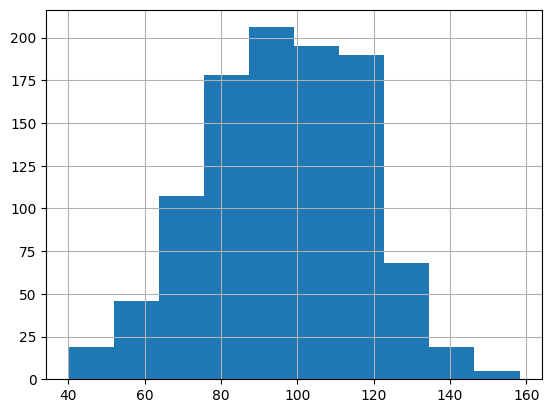

In [81]:
(long_bmi[~(long_bmi.vendor_dashboard == 'Second Genome')])['observed_features'].hist()

<Axes: >

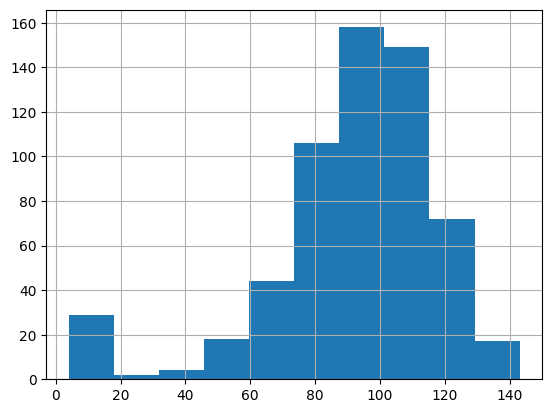

In [82]:
long_bmi[long_bmi.vendor_dashboard == 'Second Genome']['observed_features'].hist()

Interestingly, when we examine this table, all but one of the samples come from the Second Genome vendor. Not sure if that should be a coincendence?

It looks like the samples were collected between day in program 219 and 358. We can go ahead and ask later if these folks were in one batch/if there was a problem with sequencing that was previously addressed.

In [83]:
# long_bmi[long_bmi.observed_features < 35]

In [84]:
sus_fu_ids = long_bmi[long_bmi.observed_features < 35].public_client_id.tolist()
sus_fu_ids_dip = long_bmi[long_bmi.observed_features < 35][['public_client_id','days_in_program']].copy()

In [85]:
sus_fu_ids_dip.to_csv("../data/check_stool_ids.csv", index=False)

In [86]:
# len(sus_fu_ids)

In [87]:
sus_fu_ids_dip.rename(columns={'days_in_program':'days_in_program_stool'}, inplace=True)

In [88]:
medication_assessments = adi.get_snapshot('assessments_medications')
past_year = adi.get_snapshot('assessments_vitals')[[
    'public_client_id',
    'days_in_program',
    'assessment:vitals:antibiotics:enum']].copy()
past_year.dropna(
    subset=['assessment:vitals:antibiotics:enum', 'days_in_program'],
    inplace=True)
# past_year.public_client_id.nunique()

In [89]:
sus_fu_questionnaires = medication_assessments[medication_assessments.public_client_id.isin(sus_fu_ids)][[
    'public_client_id','days_in_program','meds_antibiotics_last_3_months'
]].copy()

In [90]:
sus_fu_questionnaires = sus_fu_questionnaires.sort_values(by='days_in_program')
sus_fu_ids_dip = sus_fu_ids_dip.sort_values(by='days_in_program_stool')

check_fu_q = pd.merge_asof(
    sus_fu_questionnaires, # Questionnaire
    sus_fu_ids_dip,        # Confirmed follow up stool sample days in program
    left_on='days_in_program',
    right_on='days_in_program_stool',
    by='public_client_id',
    direction='nearest'
)

In [91]:
sus_fu_questionnaires_yr = past_year[past_year.public_client_id.isin(sus_fu_ids)]

In [92]:
sus_fu_questionnaires_yr = sus_fu_questionnaires_yr.sort_values(by='days_in_program')
sus_fu_ids_dip = sus_fu_ids_dip.sort_values(by='days_in_program_stool')

check_fu_q_yr = pd.merge_asof(
    sus_fu_questionnaires_yr,  # Questionnaire
    sus_fu_ids_dip,            # Confirmed follow up stool sample days in program
    left_on='days_in_program',
    right_on='days_in_program_stool',
    by='public_client_id',
    direction='nearest'
)
check_fu_q_yr

,public_client_id,days_in_program,assessment:vitals:antibiotics:enum,days_in_program_stool
0,01045282,1.0,(2) Not in the last year,230.0
1,01148226,1.0,(0) In the last 3 months,223.0
2,01838038,1.0,(0) In the last 3 months,236.0
3,01556865,1.0,(2) Not in the last year,219.0
4,01983426,1.0,(0) In the last 3 months,231.0
5,01839338,3.0,(1) In the last 12 months,240.0
6,01157462,3.0,(2) Not in the last year,244.0
7,01975810,3.0,(2) Not in the last year,242.0
8,01990337,3.0,(2) Not in the last year,226.0
9,01864802,6.0,(2) Not in the last year,241.0


In [93]:
sus_fu_questionnaires[sus_fu_questionnaires['meds_antibiotics_last_3_months']=='Yes']

,public_client_id,days_in_program,meds_antibiotics_last_3_months
1029,01148226,1.0,Yes
5698,01838038,1.0,Yes
6717,01983426,1.0,Yes
6071,01890798,6.0,Yes
331,01048730,35.0,Yes
995,01142326,57.0,Yes


In [94]:
# check_fu_q.sort_values(by='public_client_id')

**Look at their first stool samples**

In [95]:
long_bmi[long_bmi.public_client_id.isin(sus_fu_ids)].sort_values(
    by=['public_client_id','days_in_program'])[[
    'public_client_id',
    'days_in_program',
    'observed_features',
    'vendor_dashboard',
    'abx_recency'
    ]].head()

,public_client_id,days_in_program,observed_features,vendor_dashboard,abx_recency
155,01045282,7.0,98.305627,Second Genome,none
860,01045282,230.0,13.000000,Second Genome,none
758,01048730,44.0,62.259800,Second Genome,three
1062,01048730,341.0,15.000000,Second Genome,three
725,01089482,38.0,90.467333,Second Genome,none


Hmm let's compare the first and second reads for these individuals!

**Look at the number of reads for these samples**

In [96]:
hash_counts_first = (asvs_meta_tax[
                     (asvs_meta_tax['public_client_id'] == '01983426') & 
                     (asvs_meta_tax['days_in_program'] == 8.0)]
                     ['count']).sum()

hash_counts_second = (asvs_meta_tax[
                     (asvs_meta_tax['public_client_id'] == '01983426') & 
                     (asvs_meta_tax['days_in_program'] == 231.0)]
                     ['count']).sum()

print(f'First sample processed reads: {hash_counts_first} versus second {hash_counts_second}')

First sample processed reads: 128491 versus second 37891


Hmmm, that does seem like a significant difference in the number of reads. Not sure if all cases will be that dramatic though, as this person only had 4 observed features.

**Okay let's try to do this a little more systematically**

In [97]:
outliers = long_bmi[long_bmi.public_client_id.isin(sus_fu_ids)].sort_values(
    by=['public_client_id','days_in_program'])[[
    'public_client_id',
    'days_in_program',
    'observed_features',
    'vendor_dashboard',
    'abx_recency'
    ]].copy()

outliers.set_index(['public_client_id','days_in_program'], inplace=True)

In [98]:
outliers.observed_features.mean()

54.52621743708164

In [99]:
get_counts = asvs_meta_tax[['public_client_id', 'days_in_program', 'count']].copy()
get_counts.set_index(['public_client_id','days_in_program'], inplace=True)

In [100]:
merged = get_counts.merge(
    outliers,
    left_index=True,
    right_index=True,
    how="inner"
)

merged=merged.reset_index()

In [101]:
counts = merged.groupby(
    ['public_client_id','days_in_program'], as_index=False).agg(
    {'count': 'sum'})

In [102]:
counts = counts.sort_values(by='days_in_program')
long_bmi = long_bmi.sort_values(by='days_in_program')

counts_alphas_sus = pd.merge_asof(counts, 
                                  (long_bmi.iloc[:, 0:6]).copy(),
                                  by='public_client_id',
                                  on='days_in_program',
                                  direction='nearest')

In [103]:
counts_alphas_sus = counts_alphas_sus.sort_values(['public_client_id', 'days_in_program'])
counts_alphas_sus['timepoint'] = counts_alphas_sus.groupby('public_client_id').cumcount() + 1

df_wide = counts_alphas_sus.pivot_table(
    index='public_client_id',
    columns='timepoint',
    values=['count', 'observed_features', 'berger_parker', 'shannon_index']
)

df_wide.columns = ['_'.join([str(col[0]), str(col[1])]) if isinstance(col, tuple) else col for col in df_wide.columns]

In [104]:
df_wide['delta_count'] = df_wide['count_2'] - df_wide['count_1']

In [105]:
df_wide.delta_count.mean()

# questionable = ['01822070', '01241681', '01771190']
# abx_covar[abx_covar.public_client_id.isin(questionable)].iloc[:, 0:20]

-77447.90322580645

`df_wide` will allow us to see the change in ASV count and diversity metrics between the two sample timepoints.

**Let's look at taxonomy**

In [106]:
asvs_meta_tax_small = asvs_meta_tax.copy()

In [107]:
asvs_meta_tax_small = asvs_meta_tax_small.assign(
    taxa_genus_level = 
    asvs_meta_tax_small.Kingdom.astype(str) + '_' +
    asvs_meta_tax_small.Phylum.astype(str) + '_' + 
    asvs_meta_tax_small.Class.astype(str) + '_' +
    asvs_meta_tax_small.Order.astype(str) + '_' +
    asvs_meta_tax_small.Family.astype(str) + '_' +
    asvs_meta_tax_small.Genus.astype(str))
asvs_meta_tax_small.head()

,id,hash,count,public_client_id,sex,age,days_in_program,Kingdom,Phylum,Class,Order,Family,Genus,Species,taxa_genus_level
588768,AV15-4372|AKE035,4dcf665b73efaeed3b90719bc3e199bc,9,01602320,M,47.0,-2.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Ruminococcaceae,Flavonifractor,plautii,Bacteria_Firmicutes_Clostridia_Clostridiales_R...
858652,AV15-4372|AKE035,6ad68ff5fc96cfc6682e2a1e168be827,26,01602320,M,47.0,-2.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,NaN,NaN,Bacteria_Firmicutes_Clostridia_Clostridiales_L...
771347,AV15-4372|AKE035,e42d0195cc0397b9f5dcf2cff9cb4ec5,15,01602320,M,47.0,-2.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,Blautia,NaN,Bacteria_Firmicutes_Clostridia_Clostridiales_L...
926485,AV15-4372|AKE035,be50ed57886661b3dde7d2053a0fac9b,74,01602320,M,47.0,-2.0,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Barnesiellaceae,Coprobacter,fastidiosus,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...
89488,AV15-4372|AKE035,90f5d3ad527fa6193ce386449436902a,2244,01602320,M,47.0,-2.0,Bacteria,Firmicutes,Clostridia,Clostridiales,Lachnospiraceae,Fusicatenibacter,saccharivorans,Bacteria_Firmicutes_Clostridia_Clostridiales_L...


In [108]:
asvs_meta_tax_small = asvs_meta_tax_small[['public_client_id','days_in_program','taxa_genus_level', 'Genus', 'count']]

In [109]:
asvs_meta_tax_small[asvs_meta_tax_small['public_client_id'] == '01983426']

,public_client_id,days_in_program,taxa_genus_level,Genus,count
1043479,01983426,8.0,Bacteria_Firmicutes_Clostridia_Clostridiales_R...,Fournierella,24
649375,01983426,8.0,Bacteria_Firmicutes_Clostridia_Clostridiales_C...,Christensenellaceae_R-7_group,148
374130,01983426,8.0,Bacteria_Firmicutes_Negativicutes_Selenomonada...,Phascolarctobacterium,565
446036,01983426,8.0,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,Alistipes,270
29173,01983426,8.0,Bacteria_Firmicutes_Clostridia_Clostridiales_R...,Faecalibacterium,11794
...,...,...,...,...,...
940156,01983426,231.0,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,Prevotella_9,10075
831869,01983426,231.0,Bacteria_Proteobacteria_Gammaproteobacteria_Be...,Sutterella,1721
143746,01983426,231.0,Bacteria_Firmicutes_Clostridia_Clostridiales_L...,Agathobacter,11466
19253,01983426,231.0,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,Bacteroides,10658


In [110]:
small_followup = (asvs_meta_tax_small[(asvs_meta_tax_small['public_client_id'] == '01983426') & 
                  (asvs_meta_tax_small['days_in_program'] == 231.0)])

In [111]:
first_baseline = (asvs_meta_tax_small[(asvs_meta_tax_small['public_client_id'] == '01983426') & 
                  (asvs_meta_tax_small['days_in_program'] == 8.0)]).groupby(
    "taxa_genus_level", as_index=False).agg({
    "count": "sum",
    "public_client_id": "first",
    "days_in_program": "first",
    "Genus":"first"
      })

In [112]:
taxa_first = set(first_baseline.taxa_genus_level)
taxa_second = set(small_followup.taxa_genus_level)

In [113]:
shared = list(taxa_second.intersection(taxa_first))

In [114]:
small_followup[small_followup.taxa_genus_level.isin(shared)].sort_values(by=["Genus","count"]) # .taxa_genus_level.tolist()

,public_client_id,days_in_program,taxa_genus_level,Genus,count
143746,01983426,231.0,Bacteria_Firmicutes_Clostridia_Clostridiales_L...,Agathobacter,11466
144587,01983426,231.0,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,Bacteroides,3971
19253,01983426,231.0,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,Bacteroides,10658
940156,01983426,231.0,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,Prevotella_9,10075
831869,01983426,231.0,Bacteria_Proteobacteria_Gammaproteobacteria_Be...,Sutterella,1721


In [115]:
first_baseline[first_baseline.taxa_genus_level.isin(shared)].sort_values(by=["Genus","count"])

,taxa_genus_level,count,public_client_id,days_in_program,Genus
16,Bacteria_Firmicutes_Clostridia_Clostridiales_L...,16097,01983426,8.0,Agathobacter
4,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,27498,01983426,8.0,Bacteroides
5,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,264,01983426,8.0,Prevotella_9
77,Bacteria_Proteobacteria_Gammaproteobacteria_Be...,688,01983426,8.0,Sutterella


In [116]:
first_baseline.sort_values(by=["Genus","count"]).taxa_genus_level.nunique() # Rarefied number ~ 76

78

### Drop these outliers

Okay, well, I am not very confident that I know what's going on with those samples, so let's drop them since it could be anything from concurrent antibiotics to pcr/processing errors.

In [117]:
long_bmi = long_bmi[~long_bmi.public_client_id.isin(sus_fu_ids)]

In [118]:
len(sus_fu_ids)

31

In [119]:
long_bmi[['public_client_id','abx_recency']].drop_duplicates()['abx_recency'].value_counts()

abx_recency
none      525
twelve    159
three     107
Name: count, dtype: int64

In [121]:
long_bmi.public_client_id.nunique()

791

In [125]:
long_bmi[long_bmi.dsb != 0].dsb.mean()

434.5267857142857

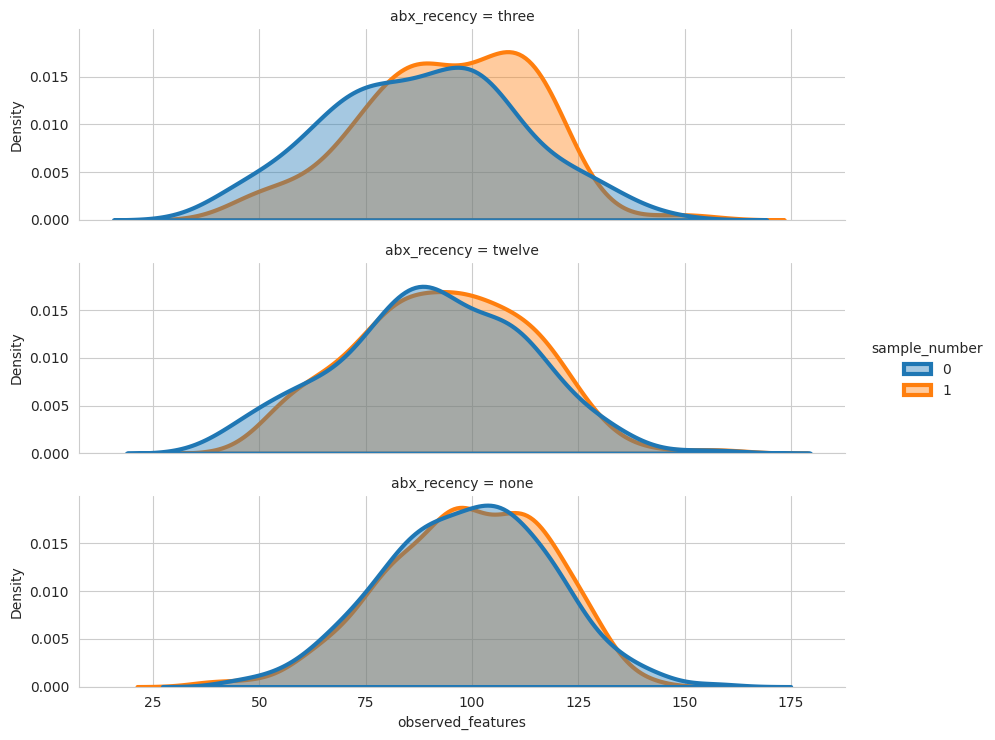

In [118]:
my_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#ccdbdc'}

palette_map = {
    "three": ["#ccdbdc", "green"],
    "twelve": ["#80ced7", "green"],
    "none": ["#007ea7", "green"],
}

sns.set_style(style="whitegrid")

row_order=["three", "twelve", "none"]

g = sns.displot(
    data=long_bmi, x="observed_features", hue="sample_number",
    row="abx_recency", row_order=row_order,
    kind="kde", height=2.5, aspect=3.5, common_norm=False,
    fill=True, linewidth=3, alpha=0.4,
)

plt.savefig("../figures/stool_follow_up_facet_dist.pdf", bbox_inches="tight")
plt.show()

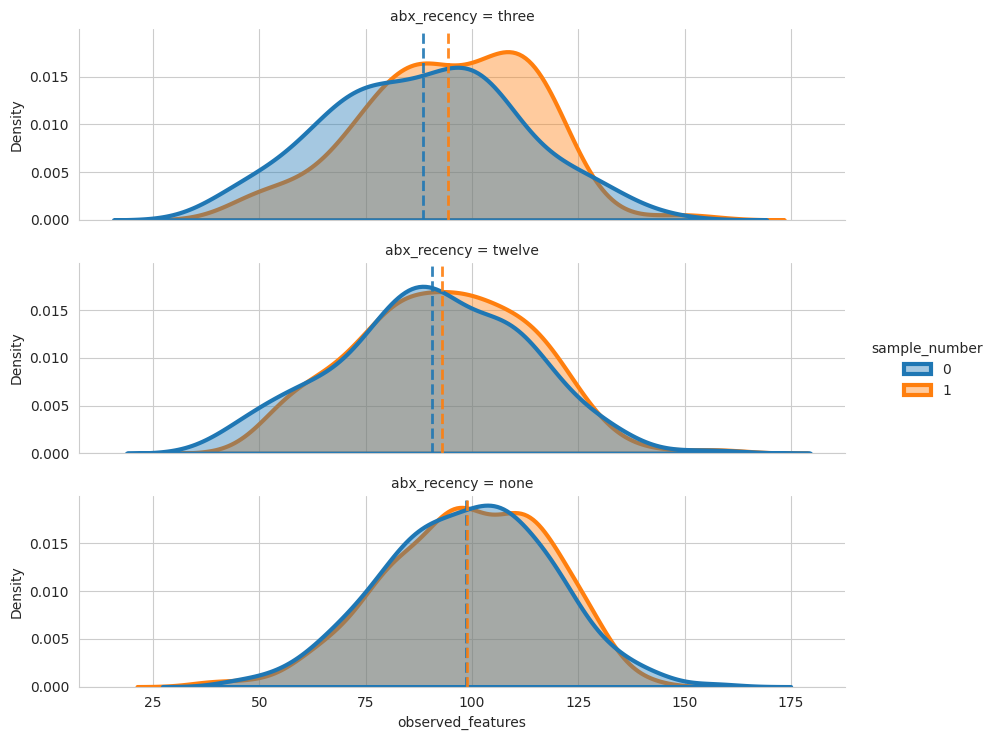

In [123]:
row_order = ["three", "twelve", "none"]
hue_order = sorted(long_bmi["sample_number"].unique())  # pin order so colors match

g = sns.displot(
    data=long_bmi, x="observed_features", hue="sample_number",
    hue_order=hue_order,
    row="abx_recency", row_order=row_order,
    kind="kde", height=2.5, aspect=3.5, common_norm=False,
    fill=True, linewidth=3, alpha=0.4,
)

# Grab the palette seaborn used so mean lines match the KDE hues
palette = sns.color_palette(n_colors=len(hue_order))
color_map = dict(zip(hue_order, palette))

for recency, ax in g.axes_dict.items():          # keyed by row value
    sub = long_bmi[long_bmi["abx_recency"] == recency]
    for hue_val in hue_order:
        m = sub.loc[sub["sample_number"] == hue_val, "observed_features"].mean()
        if pd.notna(m):
            ax.axvline(m, color=color_map[hue_val], ls="--", lw=2, alpha=0.9)

g.tight_layout()
my_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#ccdbdc'}

palette_map = {
    "three": ["#ccdbdc", "green"],
    "twelve": ["#80ced7", "green"],
    "none": ["#007ea7", "green"],
}


plt.savefig("../figures/stool_follow_up_facet_dist.pdf", bbox_inches="tight")
plt.show()

## Save final stool follow up CSV

In [120]:
long_bmi.to_csv('../data/stool_repeat_clients_long.csv', index=False)

**Also just in case, let's also look at the person who seems to have not changed at all (twelve month group).**

In [121]:
long_bmi[long_bmi.observed_features > 155].sort_values(by='public_client_id').iloc[:, 0:6]

,public_client_id,days_in_program,abx_recency,observed_features,berger_parker,shannon_index
120,01075315,7.0,none,158.201027,0.123874,3.544412
603,01602144,25.0,none,155.200148,0.202204,3.417030
336,01606409,12.0,twelve,155.780257,0.252778,3.484581
1301,01606409,407.0,twelve,157.014338,0.079201,3.795913


This is really cool to see actually. Even though person '01606409' has always had high richness, their earlier timepoint was characterized by more dominance, which would make sence if they were closer in time to the antibiotic perturbation. 